# LV: Introduction into Artificial Intelligence and Data Science 

Die vorliegende Übung soll mithilfe eines einfachen Datensatzes ermöglichen, einige grundlegenden Methoden und Fähigkeiten des klassischen maschinellen Lernens und des Lernens in neuronalen Netzen kennenzulernen und zu veranschaulichen. 

## Zum Jupyter-Notebook

Das vorliegende Jupyter-Notebook besteht aus einzelnen Zellen (cells), die nacheinander ausgeführt werden können. In Zellen mit ausführbaren Programmanweisungen (code) befinden sich entsprechend ausführbare Python-Programmanweisungen, während Text-Zellen (markdown) für Dokumentation und Beschreibungen verwendet werden.

Dabei lassen sich **ausführbare Programmanweisungen**, **Dokumentationen und Beschreibungen** übersichtlich voneinander trennen, und dennoch Programmanweisungen mit erklärenden Texten verbinden und den Ablauf der Übung nachvollziehbar strukturieren.

Eine ausgewählte Zelle oder alle Zellen können beispielsweise über das Menu des Jupyter-Notebooks ausgeführt werden. Dabei werden Zellen mit **ausführbaren Programmanweisungen** ausgeführt. Die Zellen sollten grundsätzlich in der vorgesehenen Reihenfolge ausgeführt werden, da spätere Zellen auf Variablen und Ergebnisse vorheriger Zellen zugreifen können.

Geänderte Programmzellen können jederzeit erneut ausgeführt werden. Dabei werden die Anweisungen der jeweiligen Zelle erneut ausgeführt und bereits vorhandene Variablen oder Ergebnisse gegebenenfalls überschrieben. Dies ermöglicht es, Änderungen an den Programmanweisungen direkt auszuprobieren und deren Auswirkungen zu überprüfen.

Da nachfolgende Programmzellen möglicherweise auf den veränderten Variablen oder Ergebnissen aufbauen, müssen anschließend auch alle davon abhängigen nachfolgenden Zellen erneut ausgeführt werden. Dadurch wird sichergestellt, dass die angezeigten Ergebnisse auf dem aktuellen Stand der Programmanweisungen basieren.

## Aufgabe: Erkennung der Schwertlilien-Art (Iris) anhand von Messdaten

Für die Klassifikationsaufgabe soll der **Iris-Datensatz** verwendet werden. Er enthält Messungen verschiedener Schwertlilien (Iris). 

Dokumentation : https://archive.ics.uci.edu/dataset/53/iris

Für jede Blüte wurden vier Merkmale erfasst:

* Länge des Kelchblatts (*sepal length*)
* Breite des Kelchblatts (*sepal width*)
* Länge des Blütenblatts (*petal length*)
* Breite des Blütenblatts (*petal width*)

Zusätzlich ist für jede Blüte die zugehörige Gattung als **Zielklasse (target)** angegeben. Der Datensatz umfasst drei Gattungen:

* **Iris Setosa**
* **Iris Versicolour**
* **Iris Virginica**

Unsere Aufgabe besteht darin, anhand der vier gemessenen Merkmale die Gattung einer Irisblüte zu **klassifizieren**.

Anhand der Messdaten soll jeweils ein Modell aus dem Portfolio verschiedener klassischer Ansätze des maschinellen Lernens und ein einfaches neuronales Netz trainiert werden, das die Gattung automatisch erkennen kann, wenn die entsprechenden Kron- und Kelchblattlängen und -breiten der Blüten gegeben sind.
Die Klassifikation erfolgt also nicht aufgrund der Bildinformation sondern auf messbaren Eigenschaften der Blütenblätter.

Zur Illustration einer klassischen Methode des maschinellen Lernens wird die K-Nächste-Nachbarn-Klassifikation (K-Nearest Neighbor) verwendet. 

Dokumentation: https://de.wikipedia.org/wiki/N%C3%A4chste-Nachbarn-Klassifikation

Zur Illustration einer auf neuronalen Netzen basierten Methode wird ein einfaches mehrschichtiges vorwärts gerichtetes neuronales Netz (Multi-Layer Perceptron) verwendet. 

Dokumentation: https://de.wikipedia.org/wiki/Multi-Layer-Perzeptron

Zur Lösung wird die Übung in 3 Teile aufgeteilt:
* **Teil A**: das Importieren von Bibliotheken und die Datenaufbereitung
* **Teil B**: die Klassifikation mithilfe der K-Nächste-Nachbarn-Klassifikation (K-Nearest-Neighbor Algorithmus)
* **Teil C**: die Klassifikation mithilfe eines einfachen mehrschichtigen neuronalen Netzes (Multi-Layer-Perceptron) 

### Verständnis für das Dataset

Ausgangspunkt jeder Aufgabe des maschinellen Lernens ist zunächst das Verständnis der zugrunde liegenden Daten. Bevor ein Modell trainiert werden kann, muss bekannt sein, welche Merkmale und Zielklassen der Datensatz enthält und wie diese strukturiert sind. Die folgende Darstellung illustriert die verschiedenen Iris-Gattungen und Arten ihrer Blätter, und zeigt, welche messbaren Eigenschaften für die Klassifikation herangezogen werden.

![Iris](https://www.embedded-robotics.com/wp-content/uploads/2022/01/Iris-Dataset-Classification-1024x367.png)


# Teil A
Teil A hat zum Ziel, die zu verwendenen Bibliotheken (Module, Klassen und Funktionen), die in den nachfolgenden Programmzellen benötigt werden, zu importieren, den verwendeten Datensatz vorzustellen und für die beiden zu vergleichenden Methoden zur Klassifikation aufzubereiten.

### **Task 0 Importe Verwalten**
Python stellt bereits grundlegende Funktionalitäten bereit, für die Umsetzung der Übung werden jedoch weitere **Bibliotheken mit ihren Modulen, Klassen und Funktionen** benötigt. Dazu ist die nachfolgende Programmzelle (code cell) im Laufe der Programmentwicklung um die benötigten **Importe** zu erweitern. 

In [45]:
# Task 0

#Teil A
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris                         # Task 1
from sklearn.model_selection import train_test_split           # Task 4

#Teil B
from sklearn.neighbors import KNeighborsClassifier             # Task 6
from sklearn.metrics import confusion_matrix, accuracy_score   # Task 9

#Teil C
from sklearn.preprocessing import StandardScaler               # Task 15
import keras                                                   # Task 18
from keras.models import Sequential                            
from keras.layers import Input, Dense                          
#Zufallsprozesse werden reproduzierbar gemacht:
keras.utils.set_random_seed(42)

## 

### **Datensatz zur Verfügung stellen**

Als Erstes wird der Datensatz benötigt, der für die nachfolgende Verarbeitung verwendet werden soll. Für diese Übung wird der **Iris-Datensatz** verwendet. Dieser ist bereits Bestandteil der Bibliothek **Scikit-Learn** und kann daher direkt geladen werden.

**Scikit-Learn** ist eine Open-Source-Bibliothek für maschinelles Lernen in Python. Sie stellt zahlreiche bereits implementierte Algorithmen sowie Klassen, Methoden und Funktionen für die Entwicklung und Anwendung von Machine-Learning-Modellen bereit. Darüber hinaus bietet **Scikit-Learn** verschiedene Datensätze, darunter auch den **Iris-Datensatz**.

Dokumentation zum Datensatz: https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

### **Task 1 – Scikit-Learn importieren**

Als Erstes ist dazu in der bereits oben angelegten ersten Programmzelle die Funktion zum Laden des Iris-Datensatzes aus dem Modul **datasets** zu importieren.

Dokumentation zum Datensatz: https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

### **Task 2 – Datensatz laden und untersuchen**

Nachfolgend ist der Iris-Datensatz zu laden und in einer Variablen mit dem Namen **iris** zu speichern.

Der Datensatz wird als Objekt mit verschiedenen Attributen zurückgegeben. Gebt anschließend die **Namen der Merkmale (Features)** sowie die **Bezeichnungen der Zielklassen (Targets)** aus.

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html#sklearn.datasets.load_iris

In [46]:
# Task 2
iris = load_iris()

print("Namen der Merkmale (Features):")
print(iris.feature_names)

print("\nBezeichnungen der Zielklassen (Targets):")
print(iris.target_names)

Namen der Merkmale (Features):
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Bezeichnungen der Zielklassen (Targets):
['setosa' 'versicolor' 'virginica']


### Überprüfung

Wenn der Datensatz korrekt geladen werden konnte, sollte die folgende Programmzelle korrekt ausgeführt werden. 
Der nachfolgende Python-Code kombiniert die Merkmale (features) und Zielklassen (targets) aus den Daten des Iris-Datensatzes in einer übersichtlichen Tabelle (**DataFrame**) und gibt anschließend die ersten 5 Zeilen aus.

In [47]:
# Converting the dataset to a pandas DataFrame
iris_df = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                     columns= iris['feature_names'] + ['target'])

# Display the first five rows of the DataFrame
print(iris_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0     0.0  
1     0.0  
2     0.0  
3     0.0  
4     0.0  


## Visualisierung der Merkmalsverteilung des Datensatzes

Im Folgenden wird die Verteilung der Proben im vollständigen Iris-Datensatz analysiert. Die Visualisierung stellt die Irisblüten anhand der Länge und Breite der Kelchblätter (Sepal Length und Sepal Width) im Merkmalsraum dar. Dadurch lässt sich zunächst untersuchen, inwieweit sich die drei Iris-Arten anhand dieser beiden Merkmale voneinander abgrenzen lassen.

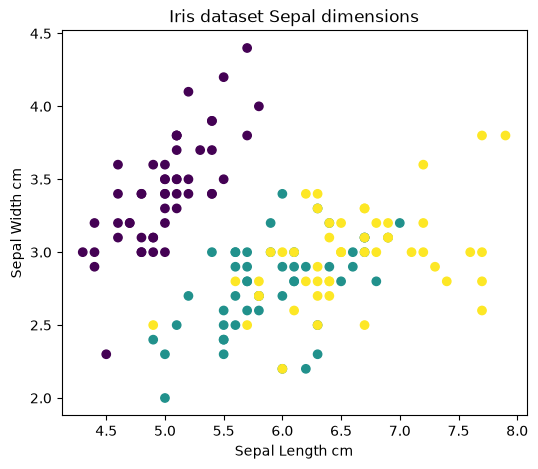

In [48]:
plt.figure(figsize=(6, 5))
plt.scatter(iris_df.iloc[:, 0], iris_df.iloc[:, 1], c=iris.target)
plt.xlabel('Sepal Length cm')
plt.ylabel('Sepal Width cm')
plt.title('Iris dataset Sepal dimensions')
plt.show()

In der Visualisierung lässt sich erkennen, dass sich die 3 Iris-Gattungen unterschiedlich im Merkmalsraum verteilen. **Setosa** (dunkelviolett/blau) bildet eine relativ klar abgegrenzte Gruppe, während sich **Versicolour** (grün) und **Virginica** (gelb) teilweise überlappen. Die beiden dargestellten Merkmale ermöglichen somit bereits eine gewisse Unterscheidung der Klassen, reichen jedoch nicht aus, um alle Blüten eindeutig voneinander zu trennen.


## Sets erstellen

Als Nächstes ist der Datensatz so aufzubereiten, dass eigenständige Variablen beziehungsweise Referenzen für die **Merkmale (features)** und **Zielklassen (targets)** verwendet werden können. Anschließend sind daraus die für die voneinander unabhängig durchzuführenden Schritte des **Modelltrainings und -testens** benötigten Teilmengen zu bilden. Dadurch können das Modelltraining und die anschließende Evaluation des Modells auf voneinander getrennten Daten durchgeführt werden.

Die Merkmale werden üblicherweise in einer Variablen mit der Bezeichnung X, die zugehörigen Zielklassen hingegen in einer Variablen mit der Bezeichnung y gespeichert. Bei diesen Variablen handelt es sich um Felder (NumPy-array).

In mehrdimensionalen Feldern beziehungsweise Matrizen werden die einzelnen Elemente über einen Zeilen- und einen Spaltenindex adressiert. Dabei repräsentiert eine Zeile typischerweise eine einzelne Probe, während die Spalten die zugehörigen Merkmale enthalten.

Diese Felder (NumPy-array) werden als Objekte aus der NumPy Bibliothek implementiert. 

Dokumentation https://numpy.org/doc/stable/user/index.html#user

In unserem Iris Datensatz werden also die Merkmale (features) der Proben als Werte in einer Zeile der Variablen X gespeichert (eine Probe je Zeile), die Zielklassen als Werte der Variablen y. Die Längen und Breiten der Kelchblätter (sepal length and width) und die Längen und Breiten der Kronblätter (petal length and width) einer vermessenen Irisblüte werden also in einer Zeile der Merkmalsmatrix X gespeichert.
Die einzelnen Proben werden also über den Zeilenindex ausgelesen, deren Merkmale über den Spaltenindex.

Die Gattungen der verschiedenen Iris (**Setosa**, **Versicolour**, **Virginica**) werden numerisch durch ganze Zahlen kodiert **Setosa** 0, **Versicolour** 1, **Virginica** 2) und als Zielklassen (targets) in der Variablen y für jede Probe gespeichert.

### ***Task 3***
In der nachfolgenden Programmzelle sind aus dem Datensatz Referenzen in den Variablen *X* und *y* zu erzeugen. Dabei ist *X* als Referenz (View) auf die ersten beiden Merkmale des Iris-Datensatzes, also die **Längen und Breiten der Kelchblätter (Sepal Length und Sepal Width)**, und *y* als Referenz auf die Zielklassen des Iris-Datensatzes anzulegen.


In [49]:
# Task 3
X = iris.data[:, :2]
y = iris.target

##### ***Erklärung:***

X = iris.data enthält alle vier Merkmale des Iris-Datensatzes:

    Sepal Length
    Sepal Width
    Petal Length
    Petal Width


Gefordert sind aber nur die ersten beiden Merkmale. 

Durch das Slicing [:, :2] entsteht bei einem NumPy-Array normalerweise ein View auf iris.data (keine unabhängige Kopie der Werte).
X enthält also von allen Zeilen (erster :) die Spalten 0 und 1 (:2), also Sepal Length und Sepal Width.

y = iris.target verweist direkt auf das Array mit den Zielklassen (0 = setosa, 1 = versicolor, 2 = virginica)

### Training- und Test-Set erstellen

Für die Modellbildung wird der Datensatz in **Trainings- und Testdaten** aufgeteilt. Die Trainingsdaten werden zum Erlernen beziehungsweise Speichern der für das jeweilige Verfahren erforderlichen Informationen verwendet. Die Testdaten bleiben während dieses Vorgangs unberücksichtigt und werden erst anschließend zur Bewertung der Modellgüte eingesetzt. Dadurch kann überprüft werden, wie gut das Modell auf bisher unbekannte Daten generalisiert.

Die Unterscheidung zwischen Trainings- und Testdaten ist wichtig, um die Generalisierungsfähigkeit des Modells beurteilen zu können.
Dazu sollen im nächsten Schritt sowohl die gespeicherten Merkmale (features) als auch deren Zielklassen (targets) aus dem Datensatz in Teilmengen zum Training *(X_train, y_train)* und Testen *(X_test, y_test)* aufgeteilt werden.

Da in diesem Fall kein separater Validierungsdatensatz verwendet wird, werden üblicherweise 80% der Daten für das Training und 20% für das abschließende Testen verwendet. Mithilfe der Trainingdaten lernen die beiden zu vergleichenden Modelle die in den Daten enthaltenen Muster und bestimmen ihre Modellparameter. Die Testdaten bleiben während des Trainings unberücksichtigt und werden erst im Anschluss verwendet, um die Modellgüte auf bisher unbekannten Daten unabhängig zu bewerten.

Für die Aufteilung des Datensatzes verwenden wir die Funktion **train_test_split** aus der **Scikit-Learn-Bibliothek**.

### **Task 4**

Als Nächstes ist die Funktion **train_test_split** aus dem entsprechenden Modul von **Scikit-Learn** in der **ersten bereits angelegten Programmzelle** zu importieren.

Die Funktion wird später verwendet, um den Datensatz in **Trainings- und Testdaten** aufzuteilen.

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

### **Task 5**

In der nachfolgenden Programmzelle sind 4 Variablen für die getrennten Trainingsdaten- und Testdaten-Mengen aus den Merkmalen (features) in der Variablen *X* und den Zielklassen (target labels) in der Variablen *y* mit den folgende Namen zu erzeugen:

1.   X_train
2.   X_test
3.   y_train
4.   y_test

Die Variablen sollen über die Funktion *train_test_split* erzeugt und befüllt werden. 

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

Um die zufällige Auswahl der Proben bei wiederholtem Aufruf der Funktion **reproduzierbar** zu machen, ist die Variable **random_state** beim Aufruf auf einen konkreten ganzzahligen Wert zu setzen.

Der Anteil der Testdaten-Menge soll 20% (0.2) betragen. 

Um sicher zu stellen, dass das Verhältnis der Klassen in der Trainings- und Testdatenmenge ungefähr dem Verhältnis im Gesamtdatensatz entspricht, wird die Variable **stratify=y** gesetzt.

In [50]:
# Task 5

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


##### ***Erklärung:***

Bedeutung der Argumente:

    X: Merkmale, hier die ersten beiden Iris-Merkmale.
    y: Zielklassen.
    test_size=0.2: 20 % der Daten werden als Testdaten verwendet.
    random_state=42: sorgt dafür, dass die zufällige Aufteilung bei jedem Programmlauf gleich ist.
    stratify=y: erhält die Klassenverteilung in Trainings- und Testdaten möglichst bei.

# Teil B K-Nächste-Nachbarn-Klassifikation (k-nearest-neighbor)
Der Teil B instanziiert, trainiert und evaluiert die K-Nächste-Nachbarn-Klassifikation (k-nearest-neighbor)

## Instanz der K-Nächste-Nachbarn-Klassifikation erstellen

Die K-Nächste-Nachbarn-Algorithmus (KNN) ist ein nicht-parametrisches Verfahren zur Klassifikation. Für eine neue, unbekannte Probe betrachtet der Algorithmus die k Trainingsproben, die dieser Probe im Merkmalsraum am ähnlichsten sind. Die Ähnlichkeit wird üblicherweise über ein Distanzmaß, beispielsweise die euklidische Distanz, bestimmt. Die Klasse der neuen Probe wird anschließend durch Mehrheitsentscheidung der k nächstgelegenen Nachbarn festgelegt.
Der entscheidende Unterschied zu einem parametrischen Modell besteht darin, dass KNN keine Modellparameter wie Gewichte lernt. Stattdessen werden die Trainingsdaten gespeichert und bei der Klassifikation herangezogen. Der Hyperparameter k bestimmt dabei, wie viele Nachbarn für die Klassifikationsentscheidung berücksichtigt werden.

Dokumentation https://de.wikipedia.org/wiki/N%C3%A4chste-Nachbarn-Klassifikation

### **Task 6**
Der KNN-Klassifikation ist bereits in der https://scikit-learn.org/ Library implementiert. Um die Klasse *KNeighborsClassifier* zu nutzen, muss sie vorab in der ersten Programmcode-Zelle importiert werden.

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html


### **Task 7**
Sowohl aus der Beschreibung als auch aus den Metadaten geht hervor, dass der Datensatz 3 Iris Gattungen beschreibt. Jede Gattung der jeweiligen Irisblüte wird numerisch durch eine eindeutige ganze Zahl kodiert: **Setosa** wird durch (0), **Versicolour** durch (1) und **Virginica** durch (2) repräsentiert. Diese kodierten Zielklassen werden als Werte der Feld-Variablen *y* (NumPy-array) für jede Probe gespeichert.

Daraus ergibt sich, dass das Klassifikationsmodell drei unterschiedliche Klassen unterscheiden bzw. erkennen können muss. Es handelt sich somit um ein Multiklassen-Klassifikationsproblem mit drei Klassen.
        
In der nachfolgenden Programmzelle ist eine Instanz der K-Nächste-Nachbarn-Klassifikation zu erzeugen. Dabei ist die Anzahl der zu berücksichtigenden Nachbarn auf *k=5* (n_neighbors) festzulegen. Der Parameter *k* (n_neighbors) bestimmt, wie viele der nächstgelegenen Trainingsproben für die Klassifikationsentscheidung herangezogen werden. Die *k* Nachbarn sind dabei jene *k* Trainingsproben, die einer neuen, unbekannten Probe im Merkmalsraum am nächsten liegen.

Bei der Klassifikation läuft das vereinfacht so ab:

1) Eine neue Probe wird dem KNN-Modell übergeben.
2) Das Modell berechnet die Distanz zwischen dieser Probe und allen Trainingsproben.
3) Die *k* nächstgelegenen Proben werden ausgewählt.
4) Die Klassen dieser Nachbarn werden betrachtet.
5) Die Klasse mit den meisten Stimmen wird als Vorhersage für die neue Probe verwendet.

Beispiel: Bei *k=5* gehören unter den fünf nächsten Nachbarn drei zur Klasse **Setosa**, einer zu **Versicolour** und einer zu **Virginica**. Die neue Probe wird daher als **Setosa** (Klasse 0) klassifiziert.

In [51]:
# Task 7
knn = KNeighborsClassifier(n_neighbors=5)

## Modell Training
Nachdem eine Instanz der K-Nächste-Nachbarn-Klassifikation erzeugt wurde, kann das Modell trainiert werden.

Beim Training des K-Nächste-Nachbarn-Klassifikators werden im Gegensatz zu parametrischen Modellen keine Modellparameter wie Gewichte gelernt. Stattdessen werden die Trainingsdaten mit ihren zugehörigen Zielklassen gespeichert. Die eigentliche Klassifikationsentscheidung erfolgt erst bei der späteren Vorhersage: Für eine unbekannte Probe (sample) werden die *k* nächstgelegenen Trainingsproben bestimmt und deren Klassen zur Vorhersage wie bereits beschrieben herangezogen.

### **Task 8**

Im der nachfolgenden Programmzelle ist das Modelltraining zu implementieren. Dazu ist die erzeugte Instanz der KNN-Klassifikation *knn* zu verwenden und deren *.fit()* Methode zu nutzen. Als Parameter für die *.fit()* Methode werden sowohl die Merkmale (features) als auch die Zielklassen (target labels) der Trainingsproben *X_train* und *y_train* übergeben.

Die Merkmale der Proben (samples), die zum Training des Modells veerwendet werden, sind bereits in der Variablen *X_train* gespeichert. Die zugehörigen Zielklassen sind in der Variablen *y_train* gespeichert.
    
Dokumentation (*.fit()*): https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.fit

In [52]:
# Task 8
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Accuracy überprüfen

Nachdem das Modell trainiert wurde, können wir mithilfe des Modells die Proben (samples) aus dem Testdatensatz auf der Basis ihrer Merkmale (features) als Iris **Setosa**, Iris **Versicolour** oder Iris **Virginica** klassifizieren. Durch den Vergleich zwischen der durch das Modell vorhergesagten (predict) Klasse und der Klassen-Referenz aus dem Test-Set lässt sich die Genauigkeit des Modells bestimmen.

Dazu sind die Merkmale der Proben (samples) aus dem Test-Set mithilfe der **.predict()** Methode zuerst zu klassifizieren. .....



### **Task 9**

Für den Test der Genauigkeit und anschließender Visualisierung müssen wir noch zwei letzte Methoden importieren: *confusion_matrix* und *accuracy_score* aus dem *metrics*-Modul der Scikit-Learn Library.

Versucht wieder über die Dokumentation selbst herauszufinden, wie der Import funktioniert.

Dokumentation (*metrics*): https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics

Dokumentation (*confusion_matrix*): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

Dokumentation (*accuracy_score*): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html



### **Task 10**

Im der nachfolgenden Programmzelle ist die Klassifikation der Proben aus dem Testdatensatz mithilfe der *.predict()* Methode der *knn* Instanz zu implementieren. Dazu sind ausschliesslich die Merkmale (features) der Proben aus dem Testdatensatz in der Variablen *X_test* zu übergeben.

Die *.predict()* Methode soll das Ergebnis in einer Variable *y_pred* speichern.

Dokumentation (*.predict()*): https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.predict

In [53]:
# Task 10
y_pred = knn.predict(X_test)

### **Task 11**

In der nachfolgenden Programmzelle ist aus dem Ergebnis der Klassifikation in der Variablen *y_pred* und der Klassenreferenz der Proben aus dem Testdatensatz *y_test* die Genauigkeit mithilfe der *accuracy_score*-Methode zu bestimmen und auszugeben.

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html

In [54]:
# Task 11

accuracy = accuracy_score(y_test, y_pred)

print(f"Genauigkeit: {accuracy:.2%}")

Genauigkeit: 76.67%


### **Task 12**
In der nachfolgenden Programmzelle soll mithilfe der **Verwechslungsmatrix** (confusion matrix) festgestellt werden, wie die vom Modell vorhergesagten Klassen mit den tatsächlichen Klassen des Testdatensatzes übereinstimmen. Sie stellt dabei die tatsächlichen Zielklassen den vom Modell vorhergesagten Klassen gegenüber. Dadurch lässt sich erkennen, wie viele Proben jeweils korrekt klassifiziert und welche Klassen miteinander verwechselt wurden. Die korrekt klassifizierten Proben befinden sich auf der **Hauptdiagonalen** der Matrix, während die Einträge außerhalb der Diagonalen **Fehlklassifikationen** darstellen.

Dazu soll die Funktion *confusion_matrix()* zu verwendet werden, welche die Verwechslungsmatrix als Feldvariable (NumPy-array) instanziiert. 

Dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html


Das Ergebnis speichern wir in einer Variable *cm*.

In [55]:
# Task 12

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10  0  0]
 [ 0  6  4]
 [ 0  3  7]]


## Visualisierung und Analyse des Modellverhaltens
Da das KNN-Modell nur mit den beiden Merkmalen **Sepal Length** und **Sepal Width** trainiert wurde, können seine Entscheidungsgrenzen in einem zweidimensionalen Koordinatensystem dargestellt werden. Dazu wird zunächst ein feines Raster über den Wertebereich der beiden Merkmale gelegt. Für jeden Punkt dieses Rasters bestimmt das KNN-Modell die vorhergesagte Iris-Gattung. Die vorhergesagten Klassen werden anschließend farblich dargestellt. Die Übergänge zwischen den farbigen Bereichen zeigen die **Entscheidungsgrenzen des KNN-Modells**.


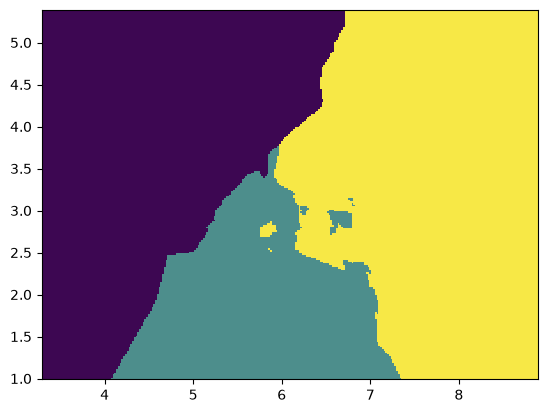

In [56]:
h = .02
cmap_light = ListedColormap(['#3D0752', '#4D8E8C', '#F7E846'])
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

### **Task 13** 
Im ersten Experiment wurde das KNN-Modell ausschließlich mit 2 Merkmalen trainiert: **Sepal Length** und **Sepal Width**. Die beiden Merkmale der Blütenblätter (**Petal Length** und **Petal Width**) wurden dabei nicht berücksichtigt.

In der nachfolgenden Programmzelle sind die Merkmale der Proben nun um die beiden zusätzlichen Merkmale zu erweitern, sodass alle 4 verfügbaren Merkmale für das Training und die Klassifikation verwendet werden können. 
Dazu ist nun die Referenz auf das Array mit sämtlichen Merkmalen des Iris-Datensatzes in der Variable *X* zu speichern, die Merkmale in der Variablen *X* und den Zielklassen (target labels) in der Variablen *y* erneut in Trainings- und Testdaten aufzuteilen und das KNN-Modell mit den 4 Merkmalen mithilfe der *.fit()* Methode zu trainieren. Anschliessend werden die Klassen der Testproben mithilfe der *.predict()* Methode klassifiziert. Abschließend sind sowohl die Genauigkeit (Accuracy) des Modells auf dem Testdatensatz als auch die Verwechslungsmatrix neu zubestimmen und auszugeben.

In [57]:
# Task 13
# Alle vier Merkmale des Iris-Datensatzes verwenden
X = iris.data
y = iris.target

# Trainings- und Testdaten erneut aufteilen
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# KNN-Modell mit k = 5 trainieren
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Klassen für die Testdaten vorhersagen
y_pred = knn.predict(X_test)

# Genauigkeit bestimmen und ausgeben
accuracy = accuracy_score(y_test, y_pred)
print(f"Genauigkeit: {accuracy:.2%}")

# Verwechslungsmatrix bestimmen und ausgeben
cm = confusion_matrix(y_test, y_pred)
print("Verwechslungsmatrix:")
print(cm)

Genauigkeit: 100.00%
Verwechslungsmatrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


### **Task 14** 
Der Iris-Datensatz stellt einen sehr einfachen und überschaubaren Datensatz dar. Er basiert auf lediglich 4 aussagekräftigen Merkmalen, deren Messwerte unter vergleichsweise kontrollierten Bedingungen erhoben wurden und daher nur in geringem Maße durch Messfehler oder Störungen der Messtechnik beeinflusst sind. Reale Datensätze weisen hingegen häufig Messunsicherheiten, Störeinflüsse und zusätzliche, für die Klassifikation nur wenig oder gar nicht relevante Merkmale auf. Um diese realistischeren Bedingungen zu simulieren, werden dem Datensatz im Folgenden gezielt Störungen und zusätzliche Rauschmerkmale hinzugefügt.

In der nachfolgenden Programmzelle soll dazu zunächst eine Kopie *X_noisy* der ursprünglichen Merkmale (features) *X* erstellt werden. Anschließend soll zu jedem Merkmalswert der Variablen *X_noisy* ein zufällig erzeugter Wert aus einer Normalverteilung mit einem Mittelwert von 0 und einer Standardabweichung von 0,8 addiert werden. Dadurch werden die Merkmale aller Proben (samples) und somit alle 3 Iris-Klassen gleichermaßen durch Rauschen beeinflusst.

Dokumentation https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html

Die Parameter sind wie folgt zu wählen:

Mittelwert: 0 keine systematische Verschiebung

Standardabweichung: 0.8 Stärke des Rauschens

Shape: genau so viele Zufallswerte wie Merkmale vorhanden sind

Der verrauschte Datensatz wird anschließend wieder wie bereits praktikziert in Trainings- und Testdaten aufgeteilt.

Das KNN-Modell wird ausschließlich mit den verrauschten Trainingsdaten trainiert. Anschließend werden die ebenfalls verrauschten Testdaten klassifiziert. Die Klassifikationsleistung ist mithilfe der Methode  *accuracy_score* zu bewerten. Zusätzlich wird die Verwechslungsmatrix mithilfe der Methode *confusion_matrix* zu erstellen und auszugeben, um zu untersuchen, wie häufig die einzelnen Iris-Klassen korrekt bzw. falsch klassifiziert wurden.


In [58]:
# Task 14

# Optional: Zufallszahlengenerator für reproduzierbares Rauschen festlegen
np.random.seed(42)

# Kopie der ursprünglichen Merkmale mit allen vier Iris-Merkmalen erzeugen
X_noisy = X.copy()

# Gaußsches Rauschen erzeugen und zu jedem Merkmalswert addieren
noise = np.random.normal(
    loc=0,                 # Mittelwert
    scale=0.8,             # Standardabweichung
    size=X_noisy.shape     # gleiche Form wie X_noisy
)

X_noisy = X_noisy + noise

# Verrauschte Daten in Trainings- und Testdaten aufteilen
X_noisy_train, X_noisy_test, y_train, y_test = train_test_split(
    X_noisy,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# KNN-Modell erzeugen und ausschließlich mit verrauschten Trainingsdaten trainieren
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_noisy_train, y_train)

# Klassen der verrauschten Testdaten vorhersagen
y_pred = knn.predict(X_noisy_test)

# Accuracy berechnen und ausgeben
accuracy = accuracy_score(y_test, y_pred)
print(f"Genauigkeit mit Rauschen: {accuracy:.2%}")

# Verwechslungsmatrix berechnen und ausgeben
cm = confusion_matrix(y_test, y_pred)

print("Verwechslungsmatrix mit Rauschen:")
print(cm)

Genauigkeit mit Rauschen: 66.67%
Verwechslungsmatrix mit Rauschen:
[[10  0  0]
 [ 1  5  4]
 [ 0  5  5]]


## Experimentieren
Zum Experimentieren kann der **k-Wert** des Algorithmus verändert werden. Dabei ist von Interesse, wie sich unterschiedliche *k*-Werte auf die **Entscheidungsgrenzen** und die **Genauigkeit** des Modells auswirken.

Wenn ich k=7 setze, sinkt die Genauigkeit auf 96.67%
Die Entscheidungsgrenzen verschieben sich auch minimal. Ich habe ein Bild davon gemacht.

# Teil C mehrschichtes Perzeptron (multi-layer perceptron)
Teil C instanziiert, trainiert und evaluiert die auf einem mehrschichten Perzeptron (multi-layer perceptron) basierte Klassifikation der Iris-Gattungen.

Das Multilayer Perceptron (MLP) ist ein parametrisches künstliches neuronales Netz, das aus mehreren miteinander verbundenen Schichten von Neuronen besteht. Für die vorliegende Klassifikationsaufgabe werden die 4 Merkmale einer Irisblüte als Eingabe verwendet. Die Eingabeschicht besitzt daher vier Eingabewerte.

Auf die Eingabeschicht folgen eine oder mehrere verdeckte Schichten (hidden layers). Die Neuronen dieser Schichten führen gewichtete Summen der Eingabewerte beziehungsweise der Ausgaben der vorhergehenden Schicht durch und wenden darauf eine Aktivierungsfunktion an. Durch die mehreren Schichten kann das MLP komplexere Zusammenhänge zwischen den Merkmalen und den Zielklassen erlernen.

Die Ausgabeschicht besteht aus drei Ausgabeneuronen, da der Datensatz drei Iris-Gattungen unterscheidet. Jedes Ausgabeneuron steht für eine der Klassen **Setosa**, **Versicolour** und **Virginica**. Die Klasse mit der höchsten Ausgabe wird als Vorhersage des Modells verwendet.

Im Gegensatz zum K-Nächste-Nachbarn-Algorithmus lernt das MLP beim Training Modellparameter. Dazu gehören insbesondere die Gewichte und Bias-Werte der Verbindungen zwischen den Neuronen. Diese Parameter werden anhand der Trainingsdaten schrittweise angepasst, sodass die Vorhersagen des Modells möglichst gut mit den vorgegebenen Zielklassen übereinstimmen.

Dokumentation https://scikit-learn.org/stable/modules/neural_networks_supervised.html

Vor dem Training des MLP müssen die Merkmale mit dem **StandardScaler** standardisiert werden. Dabei wird jedes Merkmal unabhängig von den anderen Merkmalen so transformiert, dass es einen Mittelwert von 0 und eine Standardabweichung von 1 besitzt. Dadurch befinden sich die 4 Merkmale auf einer vergleichbaren Skala. Dies kann insbesondere bei der Optimierung der Gewichte eines neuronalen Netzes zu einem stabileren und effizienteren Training beitragen.

Für die Berechnung der Skalierungsparameter werden ausschließlich die **Trainingsdaten** verwendet. Die dabei ermittelten Mittelwerte und Standardabweichungen werden anschließend unverändert auf die **Testdaten** angewendet. Dadurch wird verhindert, dass Informationen aus dem Testdatensatz in das Training einfließen.


### **Task 15**
Der *StandardScaler* ist bereits in der https://scikit-learn.org/ Bibliothek implementiert. Um die Klasse *StandardScaler* zu nutzen, muss sie vorab in der ersten Programmcode-Zelle importiert werden.

Dokumentation https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler

### **Task 16**
Um den *StandardScaler* anzuwenden, ist dieser zunächst zu instanziieren. Anschließend werden der Mittelwert und die Standardabweichung jedes Merkmals anhand der **Trainingsdaten** mithilfe der *.fit()* Methode bestimmt. Diese Werte werden verwendet, um die Trainingsdaten mithilfe der *.transform()* Methode zu standardisieren. Alternativ kann für die **Trainingsdaten** auch die kompakte Version *.fit_transform()* verwendet werden. Die ermittelten Skalierungsparameter werden anschließend auch für die Transformation der Testdaten mithilfe der *.transform()* Methode verwendet.

An dieser Stelle ist zu beachten, dass die *.fit()* Methode des *StandardScaler* nach der Aufteilung des Datensatzes in Trainings- und Testdaten, und unter Verwendung der in der Variablen X gespeicherten Merkmale erfolgt.

Dokumentation https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler


In [59]:
# Task 16

# X enthält alle vier Merkmale des Iris-Datensatzes wieder unverrauscht
X = iris.data
y = iris.target

# Zuerst Daten aufteilen
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# StandardScaler erzeugen
scaler = StandardScaler()

# Mittelwert und Standardabweichung nur anhand der Trainingsdaten bestimmen
# und X_train standardisieren
X_train_scaled = scaler.fit_transform(X_train)

# NUR ZUM VERSTÄNDNIS: Anzeigen wie sich scaler verändert hat
print("Gelernte Mittelwerte:", scaler.mean_)
print("Gelernte Standardabweichungen:", scaler.scale_)

# Testdaten mit den aus X_train bestimmten Skalierungsparametern standardisieren
X_test_scaled = scaler.transform(X_test)


Gelernte Mittelwerte: [5.84166667 3.04833333 3.77       1.205     ]
Gelernte Standardabweichungen: [0.837415   0.44665112 1.761136   0.75947899]


### **Task 17**
Für die Lösung der Klassifikationsaufgabe mithilfe eines Multilayer Perceptron (MLP) mit Keras definiert:

Das MLP wird als *Sequential*-Modell aufgebaut, bei dem die Schichten nacheinander angeordnet sind. Die erste und zweite Schicht sind jeweils vollständig verbundene (`Dense`) Schichten mit **10 Neuronen** und verwenden die **ReLU-Aktivierungsfunktion**. Diese beiden verdeckten Schichten (hidden layers) ermöglichen es dem Modell, nichtlineare Zusammenhänge zwischen den vier Iris-Merkmalen zu erlernen.

Die letzte Schicht besitzt **drei Neuronen**, da die Klassifikation zwischen den drei Iris-Gattungen **Setosa**, **Versicolour** und **Virginica** unterscheiden muss. Als Aktivierungsfunktion wird **Softmax** verwendet. Dadurch werden die 3 Ausgaben als Wahrscheinlichkeiten für die jeweilige Klasse interpretiert. Die Summe der 3 Ausgabewerte beträgt dabei 1. Die Klasse mit der höchsten Wahrscheinlichkeit wird als vorhergesagte Klasse ausgewählt.

Damit besteht das MLP aus einer Eingabeschicht (input layer) mit vier Merkmalen, zwei verdeckten Schichten (hidden layers) mit jeweils zehn Neuronen und einer Ausgabeschicht (output layer) mit drei Neuronen.

Zur Implementierung wird das Keras API verwendet. Dazu sind in der ersten Programmzelle die ensprechende Pakete aus der Bibliothek zu importieren.

Dokumentation https://www.tensorflow.org/guide/keras/sequential_model

Desweiteren ist nachdem Importieren der Keras API der Zufallszahlengenerator mithilfe von *keras.utils.set_random_seed(42)* auf einen definierten Ausgangszustand zu setzen. Dadurch werden die verwendeten Zufallsprozesse bei wiederholter Ausführung unter gleichen Bedingungen reproduzierbar.

### **Task 18**
Die Anzahl der Neuronen in den verdeckten Schichten (hidden layers) wird nicht durch die Anzahl der Klassen vorgegeben, sondern stellt einen Hyperparameter des MLP dar. Für den ersten Versuch werden 2 verdeckte Schichten (hidden layers) mit jeweils 10 Neuronen verwendet. Die Ausgabeschicht besitzt hingegen aufgrund der 3 zu unterscheidenden Iris-Gattungen genau 3 Neuronen.

Die **ReLU-Aktivierungsfunktion (rectified linear unit)** wird in den verdckten Schichten (hidden layers) des MLP verwendet, weil sie dem neuronalen Netz ermöglicht, nichtlineare Zusammenhänge zwischen den Merkmalen zu modellieren.

Instanziiere das MLP mithilfe der **Sequential** Klasse aus dem Keras Paket. Dabei werden die einzelnen Schichten des neuronalen Netzes in ihrer Reihenfolge aufgelistet. Definiere das Modell aus 2 verdeckten Schichten (hidden layers) mit jeweils 10 Neuronen und der ReLU-Aktivierungsfunktion sowie einer Ausgabeschicht mit 3 Neuronen und der Softmax-Aktivierungsfunktion.

In [60]:
# Task 18
# Das Modell wird erzeugt, es erhält (das ist automatisch voreingestellt) zufällig erzeugte, kleine Gewichte! 
# Die Aktivierungsfunktion ReLU macht aus negativen Werten 0 und lässt positive Werte unverändert.
# Softmax wandelt die drei Ausgabewerte in Wahrscheinlichkeiten für die drei Iris-Klassen um.
model = Sequential([
    Input(shape=(4,)),
    Dense(10, activation="relu"),
    Dense(10, activation="relu"),
    Dense(3, activation="softmax")
])

### **Task 19**
Nachdem die einzelnen Schichten des MLP definiert wurden, ist das Modell in der nachfolgenden Programmzelle mit der Methode **.compile()** für das Training zu konfigurieren. Dabei werden insbesondere die Loss-Funktion und der Optimierungsalgorithmus festgelegt. Die Loss-Funktion bestimmt, wie groß der Fehler der Vorhersagen ist, während der Optimierungsalgorithmus festlegt, wie die trainierbaren Modellparameter angepasst werden, um diesen Fehler zu reduzieren. Zusätzlich wird mit **accuracy** eine Metrik festgelegt, anhand derer die Klassifikationsleistung während des Trainings beobachtet werden kann.
    
Dokumentation https://keras.io/api/models/model_training_apis/

Als Loss-Funktion wird **sparse_categorical_crossentropy** verwendet. Diese Loss-Funktion eignet sich für Klassifikationsaufgaben mit mehreren Klassen, wenn die Zielklassen als ganzzahlige Werte vorliegen. Dies entspricht der Kodierung unseres Iris-Datensatzes, bei der **Setosa**, **Versicolour** und **Virginica** durch die Werte 0, 1 und 2 im Gegensatz zu einer One-Hot Vektorkodierung bei der die Werte **Setosa**, **Versicolour**, **Virginica**  als [1, 0, 0], [0, 1, 0] and [0, 0, 1] repräsentiert werden. Die Loss-Funktion bewertet dabei, wie gut die vom MLP vorhergesagten Klassenwahrscheinlichkeiten mit der tatsächlichen Zielklasse übereinstimmen. Ein hoher Fehler entsteht insbesondere dann, wenn das Modell der tatsächlich richtigen Klasse eine geringe Wahrscheinlichkeit zuweist.

Als Optimierungsalgorithmus wird Adam (Adaptive Moment Estimation) verwendet. Adam passt die trainierbaren Modellparameter des MLP, insbesondere die Gewichte und Bias-Werte, während des Trainings schrittweise an. Grundlage hierfür sind die durch Backpropagation berechneten Gradienten der Loss-Funktion. Dabei berücksichtigt Adam sowohl den aktuellen Gradienten als auch dessen bisherige Entwicklung und bestimmt daraus für die einzelnen Parameter adaptive Aktualisierungsschritte. Dadurch kann der Optimierungsprozess effizient an die unterschiedlichen Parameter des neuronalen Netzes angepasst werden.

Dokumentation https://keras.io/api/optimizers/adam/

Als Metrik zur Bewertung der Klassifikationsleistung wird die **Genauigkeit (accuracy)** verwendet. Sie beschreibt den Anteil der korrekt klassifizierten Proben (samples) an der Gesamtzahl der betrachteten Proben. Eine Genauigkeit von 1 beziehungsweise 100% bedeutet, dass alle Proben korrekt klassifiziert wurden, während eine Accuracy von 0,5 bedeutet, dass die Hälfte der Proben korrekt klassifiziert wurde.

Die **Genauigkeit (accuracy)** ist für den vorliegenden Iris-Datensatz eine geeignete Metrik, da die drei Zielklassen annähernd gleich häufig vertreten sind. Dadurch wird die Gesamtgenauigkeit nicht wesentlich durch eine einzelne, überrepräsentierte Klasse beeinflusst.

Dokumentation https://keras.io/api/metrics/

In [61]:
# Task 19
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

### **Task 20**
Nach der erfolgreichen Konfiguration des MLP, sind die Modelparameter mit der Methode **.fit()** zu trainieren. Dabei werden die Merkmale mittels der Variablen X_train und die zugehörigen Zielklassen mittels der Variable y_train der skalierten Trainingsdaten übergeben. Das Training soll über 100 Epochen durchgeführt werden. Eine Epoche entspricht dabei einer vollständigen Verarbeitung des Trainingsdatensatzes. Die Trainingsproben werden mit einer Batch-Größe von 8 verarbeitet, sodass die Modellparameter nach jeweils acht Trainingsproben aktualisiert werden. Während des Trainings werden die Parameter des MLP mithilfe von Backpropagation und des Adam-Optimierers schrittweise angepasst, um die **Verlust-Funktion (loss function)** zu minimieren.

Dokumentation https://keras.io/api/models/model_training_apis/

Steuere die Ausgaben von Informationen während des Trainings mithilfe der **verbose=1** Parameter der **.fit()** Methode. Dabei wird für jede Epoche ein Fortschrittsbalken mit den aktuellen Trainingsmetriken, beispielsweise **Verlust-Funktion (loss function)** und **Genauigkeit (accuracy)**, ausgegeben.



***Erklärung:***

Die batch_size (Batchgröße) bestimmt, wie viele Datenbeispiele das Modell anschaut, bevor es seine internen Gewichte (sein „Wissen“) das erste Mal anpasst.

Das Netz bekommt 8 standardisierte Datensätze (X_train_scaled) vorgelegt, berechnet die Vorhersage, vergleicht sie mit den echten Ergebnissen (y_train) und aktualisiert die Gewichte. Erst dann folgen die nächsten 8. Warum 8? Eine kleinere Batchgröße sorgt dafür, dass das Netz sehr oft lernt und der Speicher (RAM) deines Computers nicht überlastet wird.

Eine Epoche (epoch) ist abgeschlossen, wenn das Modell jeden einzelnen Datensatz aus dem Trainingsset genau einmal gesehen und verarbeitet hat.

Das Modell wiederholt den kompletten Trainingsprozess 100-mal. Mit jeder Epoche versteht das MLP die Muster in deinen Daten etwas besser und die Vorhersagen werden genauer (der Fehler sinkt).

Ich habe den epoch Wert mal auf 200 gesetzt wodurch die accuracy noch mal erhöht werden konnte und der loss abgenommen hat. Das hat die Genauigkeit bei den Testdaten aber nicht erhöht!

In [62]:
# Task 20
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3333 - loss: 1.2890  
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3833 - loss: 1.1522 
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5333 - loss: 1.0390 
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7250 - loss: 0.9436 
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7583 - loss: 0.8628 
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7750 - loss: 0.7922 
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7917 - loss: 0.7299 
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8083 - loss: 0.6736 
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8167 - loss: 0.6223 
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8167 - loss: 0.5732 
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8167 - loss: 0.5317 
Epoch 12/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

***Erklärung:*** 

**batch_size=8:** Das Modell verarbeitet jeweils 8 Proben aus X_train_scaled, berechnet die Vorhersagen, vergleicht sie mit y_train und passt danach die Gewichte und Bias-Werte an. Bei 120 Trainingsproben sind das 15 Anpassungen pro Epoche.

**epochs=100:** Eine Epoche ist abgeschlossen, wenn jede Trainingsprobe einmal verarbeitet wurde. Das Training läuft über 100 Epochen, insgesamt also 1.500 Anpassungen. Der Loss auf den Trainingsdaten sinkt dabei tendenziell, die Trainingsgenauigkeit steigt.

**Beobachtung:** Mit 200 statt 100 Epochen sanken der Loss und stieg die Genauigkeit auf den Trainingsdaten weiter, die Genauigkeit auf den Testdaten verbesserte sich aber nicht. Längeres Training passt das Modell also stärker an die Trainingsdaten an, ohne die Generalisierung auf unbekannte Daten zu verbessern.

### **Task 21**
Nach dem Training der Modelparameter ist das Model mithilfe der Testdaten zu evaluieren. Dazu werden zunächst mit **mlp.predict(X_test)** für alle Proben des Testdatensatzes Vorhersagen erzeugt. Das MLP liefert dabei für jede Probe drei Ausgabewerte, die aufgrund der verwendeten Softmax-Aktivierungsfunktion als Wahrscheinlichkeiten für die drei Iris-Klassen interpretiert werden können.

Dokumentation https://keras.io/api/models/model_training_apis/

Mit **np.argmax(y_pred, axis=1)** wird anschließend für jede Probe die Klasse mit der höchsten Wahrscheinlichkeit ausgewählt. Dadurch entstehen die vorhergesagten Klassen **y_pred_classes**, die mit den tatsächlichen Zielklassen **y_test** verglichen werden können.

Dokumentation https://numpy.org/doc/stable/reference/generated/numpy.argmax.html

Die Funktion **accuracy_score()** berechnet aus den tatsächlichen und vorhergesagten Klassen die Accuracy des Modells auf dem Testdatensatz. Sie gibt somit den Anteil der korrekt klassifizierten Testproben an.

Dokumentation https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html#sklearn.metrics.accuracy_score

Anschließend wird mit **confusion_matrix()** eine Konfusionsmatrix erstellt. Sie stellt gegenüber, welche tatsächlichen Klassen vorlagen und welchen Klassen das Modell die Testproben zugeordnet hat. Dadurch lässt sich neben der Gesamt-Genauigkeit (accuracy) auch erkennen, zwischen welchen Iris-Gattungen das Modell möglicherweise Schwierigkeiten bei der Unterscheidung hat.

Dokumentation https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

Zur Evaluierung der Vorhersagen werden wie im obigen Beispiel die gleichen Methoden herangezogen.

In [63]:
# Task 21
# Für jede Testprobe drei Klassenwahrscheinlichkeiten vorhersagen
y_pred = model.predict(X_test_scaled)

# Klasse mit der höchsten vorhergesagten Wahrscheinlichkeit auswählen
y_pred_classes = np.argmax(y_pred, axis=1)

# Accuracy berechnen und ausgeben
accuracy = accuracy_score(y_test, y_pred_classes)

print(f"Test-Genauigkeit: {accuracy:.2%}")

# Verwechslungsmatrix erstellen und ausgeben
cm = confusion_matrix(y_test, y_pred_classes)

print("Verwechslungsmatrix:")
print(cm)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Test-Genauigkeit: 96.67%
Verwechslungsmatrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


### **Task 22**
In der nachfolgenden Zelle sind das Training und das Testen unter Verwendung des durch Störungen und zusätzliche Rauschmerkmale veränderten Datensatzes zu wiederholen.
Um Unterschiede zwischen den verrauschten Datensätzen zu vermeiden, sollen für das MLP die **bereits für den K-Nächste-Nachbarn-Versuch verrauschten Merkmale** (X_noisy_train, X_noisy_test) verwendet werden. Dadurch werden beide Modelle unter identischen Datenbedingungen trainiert und getestet, sodass die erzielten Ergebnisse direkt miteinander verglichen werden können.


In [64]:
# Task 22
# Verwendet werden die bereits in Task 14 erzeugten X_noisy_train und X_noisy_test,
# damit KNN und MLP mit denselben verrauschten Daten verglichen werden.

# Reproduzierbarkeit sicherstellen
keras.utils.set_random_seed(42)

# Verrauschte Trainingsdaten standardisieren
scaler_noisy = StandardScaler()

X_noisy_train_scaled = scaler_noisy.fit_transform(X_noisy_train)
X_noisy_test_scaled = scaler_noisy.transform(X_noisy_test)

# Neues MLP erzeugen
# Ein neues Modell ist nötig, damit nicht mit dem zuvor auf sauberen Daten
# trainierten MLP weitertrainiert wird.
mlp_noisy = Sequential([
    Input(shape=(4,)),
    Dense(10, activation="relu"),
    Dense(10, activation="relu"),
    Dense(3, activation="softmax")
])

# Modell konfigurieren
mlp_noisy.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Modell ausschließlich mit verrauschten Trainingsdaten trainieren
history_noisy = mlp_noisy.fit(
    X_noisy_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1
)

# Klassenwahrscheinlichkeiten für die verrauschten Testdaten vorhersagen
y_pred_noisy = mlp_noisy.predict(X_noisy_test_scaled)

# Wahrscheinlichkeiten in Klassenindizes 0, 1 oder 2 umwandeln, bzw. Klassen mit der höchsten Wahrscheinlichkeit auswählen
y_pred_noisy_classes = np.argmax(y_pred_noisy, axis=1)

# Genauigkeit bestimmen
accuracy_noisy = accuracy_score(y_test, y_pred_noisy_classes)

print(f"Test-Genauigkeit des MLP mit Rauschen: {accuracy_noisy:.2%}")

# Verwechslungsmatrix bestimmen
cm_noisy = confusion_matrix(y_test, y_pred_noisy_classes)

print("Verwechslungsmatrix des MLP mit Rauschen:")
print(cm_noisy)


Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3500 - loss: 1.2081  
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3917 - loss: 1.1285 
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4583 - loss: 1.0645 
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4833 - loss: 1.0080 
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5583 - loss: 0.9569 
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6083 - loss: 0.9100 
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6250 - loss: 0.8668 
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6333 - loss: 0.8263 
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6333 - loss: 0.7888 
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6417 - loss: 0.7539 
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6583 - loss: 0.7205 
Epoch 12/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

### **Task 23**
Die Beobachtungen aus der Evaluierung der verschiedenen Modelle sollen hier zusammengefasst werden. Fokussiert auf den Einfluss der Anzahl der verwendeten Merkmale, Art des Modells (KNN versus MLP) und dem Effekt, den das Hinzufügen der Störung mit unterschiedlicher Standardabweichung auf das Gesamtergebnis hat. Um den Einfluss der Störung zu variieren, kann die Standard-Abweichung in Task 13 auf unterschiedliche Werte beispielsweise zwischen 0.1 und 0.9 gesetzt werden.

Da das Rauschen zufällig erzeugt wird, kann die Klassifikationsgenauigkeit der beiden Modelle von einem Durchlauf zum nächsten variieren. Je nach erzeugtem Rauschmuster kann daher einmal das MLP und ein anderes Mal das K-Nächste-Nachbarn-Verfahren eine höhere Genauigkeit erreichen. Ein einzelner Versuch erlaubt somit keine allgemeingültige Aussage darüber, welches Modell robuster gegenüber dem Rauschen ist.

Um einen aussagekräftigeren Vergleich zu ermöglichen, kann das Experiment mehrfach mit unterschiedlichen Rauschmustern durchgeführt und anschließend beispielsweise die **mittlere Genauigkeit** der beiden Modelle verglichen werden.


##### ***Zusammenfassung der Beobachtungen***

In den Experimenten wurde untersucht, wie sich

    die Anzahl der verwendeten Merkmale,
    das gewählte Klassifikationsmodell (KNN oder MLP) und
    künstlich hinzugefügtes Rauschen


auf die Klassifikationsgenauigkeit des Iris-Datensatzes auswirken.


### ***1. Einfluss der Anzahl der Merkmale***

Im ersten KNN-Experiment wurden nur zwei Merkmale verwendet:

    Sepal Length
    Sepal Width


Mit diesen beiden Merkmalen lassen sich insbesondere die Klassen Versicolour und Virginica häufig nicht eindeutig voneinander trennen. Die Klasse Setosa ist meist bereits mit diesen Merkmalen gut klassifizierbar, da sie sich deutlich von den anderen beiden Klassen unterscheidet.

Bei Verwendung aller vier Merkmale

    Sepal Length,
    Sepal Width,
    Petal Length,
    Petal Width


verbessert sich die Klassifikationsleistung in der Regel deutlich. Besonders die Merkmale der Blütenblätter (Petal Length und Petal Width) enthalten wichtige Informationen zur Unterscheidung von Versicolour und Virginica.

Mit nur Sepal Length und Sepal Width erreichte KNN eine Accuracy von 76,67 % (Task 11). 7 der 30 Testproben wurden falsch klassifiziert, und alle Fehler waren Verwechslungen zwischen Versicolour und Virginica (Task 12).
Mit allen vier Merkmalen stieg die Accuracy auf 100 %, alle 30 Testproben wurden richtig klassifiziert (Task 13).
Die zusätzlichen Merkmale Petal Length und Petal Width verbessern die Trennbarkeit der Klassen, weil sich Versicolour und Virginica vor allem in der Größe der Blütenblätter unterscheiden.


### ***2. Vergleich von KNN und MLP***

Das KNN-Verfahren und das MLP verfolgen unterschiedliche Ansätze.

*KNN:*

KNN speichert die Trainingsdaten und sucht bei einer Testprobe die nächstgelegenen Trainingsproben. Die Klasse wird aus den Klassen dieser Nachbarn bestimmt.

Eigenschaften von KNN:

    einfaches Verfahren,
    keine aufwendige Trainingsphase,
    abhängig von Abständen zwischen Datenpunkten,
    empfindlich gegenüber der Skalierung der Merkmale (die Klassifikation basiert unmittelbar auf Distanzberechnungen zwischen Datenpunkten!),
    kann durch Rauschen beeinflusst werden, weil sich die Abstände zwischen Proben verändern.


Bei verrauschten Daten können sich Proben im Merkmalsraum verschieben. Dadurch können die fünf nächsten Nachbarn einer Testprobe teilweise aus einer anderen Klasse stammen. Dies kann zu Fehlklassifikationen führen.

*MLP:*

Das MLP lernt während des Trainings Gewichte und Bias-Werte. Es versucht, nichtlineare Entscheidungsgrenzen zwischen den Klassen zu lernen.

Eigenschaften des MLP:

    benötigt eine Trainingsphase,
    profitiert von standardisierten Eingabedaten (einzelne Merkmale können die Aktivierungen in den verdeckten Schichten dominieren),
    kann komplexere, nichtlineare Zusammenhänge modellieren,
    Ergebnisse hängen unter anderem von Initialisierung, Anzahl der Epochen, Netzwerkarchitektur und Optimierer ab,
    kann bei kleinen Datensätzen und ungünstigen Einstellungen ebenfalls schwanken oder overfitten.  
    
    Ein MLP kann bei kleinen Datensätzen overfitten, weil es zahlreiche trainierbare Gewichte und Bias-Werte besitzt (in unserem Fall 4x10 Gewichte + 10 Bias in der ersten Schicht, 10x10 Gewichte + 10 Bias in der 2. Schicht, 10x3 Gewichte +3 Bias in der letzten Schicht ergibt 193 Parameter, die trainiert werden!). Bei wenigen Trainingsbeispielen besteht die Gefahr, dass das Netzwerk neben den tatsächlichen Klassenmustern auch zufällige Eigenschaften, Messfehler oder künstlich hinzugefügtes Rauschen lernt. Dadurch kann eine hohe Trainingsgenauigkeit entstehen, während die Genauigkeit auf unbekannten Testdaten geringer bleibt. Zusätzlich können zufällige Gewichtsinitalisierung, die Reihenfolge der Mini-Batches und unterschiedliche Rauschmuster zu schwankenden Ergebnissen führen. Maßnahmen wie ein kleineres Netzwerk, Validierungsdaten, Early Stopping, Regularisierung und Kreuzvalidierung können Overfitting und instabile Ergebnisse reduzieren.


### ***3. Einfluss von Rauschen***

Das Rauschen wird zu jedem Merkmalswert addiert:

python
noise = np.random.normal(loc=0, scale=standardabweichung, size=X.shape)
X_noisy = X + noise


Dabei gilt:

    loc=0: Das Rauschen hat keine systematische Verschiebung.
    scale: Gibt die Stärke des Rauschens an.
    Eine größere Standardabweichung führt zu stärkeren zufälligen Veränderungen der Merkmalswerte.


Bei einer kleinen Standardabweichung, beispielsweise:

python
scale = 0.1


sind die Merkmale nur leicht verändert. Die Klassifikationsgenauigkeit bleibt daher typischerweise ähnlich wie beim ursprünglichen Datensatz.

Bei einer mittleren Standardabweichung, beispielsweise:

python
scale = 0.5


werden die Klassen stärker überlagert. Die Accuracy sinkt häufig, und in der Verwechslungsmatrix treten mehr Einträge außerhalb der Hauptdiagonalen auf.

Bei starkem Rauschen, beispielsweise:

python
scale = 0.8


oder

python
scale = 0.9


werden die ursprünglichen Merkmalsstrukturen deutlich verfälscht. Dadurch verschlechtert sich die Klassifikationsleistung in der Regel weiter.

Eine mögliche qualitative Beobachtung ist:

Effekte von unterschiedlicher Standardabweichung des Rauschens:

0.1 ->	geringe Veränderung, Accuracy meist weiterhin hoch

0.3	-> leichte Verschlechterung möglich

0.5	-> deutlichere Überlappung der Klassen, mehr Fehler

0.8	-> spürbarer Rückgang der Accuracy

0.9	-> starke Störung, Klassen sind deutlich schwieriger trennbar


Die tatsächlich gemessenen Werte hängen jedoch vom jeweiligen zufällig erzeugten Rauschmuster ab.


### ***4. Interpretation der Verwechslungsmatrix***

Die Verwechslungsmatrix zeigt nicht nur die gesamte Accuracy, sondern auch, welche Klassen verwechselt werden.

Beim Iris-Datensatz ist häufig zu beobachten:

    Setosa wird meist sehr zuverlässig erkannt.
    Versicolour und Virginica werden häufiger miteinander verwechselt.
    Mit zunehmendem Rauschen nehmen insbesondere die Fehlklassifikationen zwischen Versicolour und Virginica zu.


Eine beispielhafte Matrix könnte etwa folgende Struktur haben:

python
[[10  0  0]
 [ 0  8  2]
 [ 0  3  7]]


Interpretation:

    Alle 10 Setosa-Proben wurden korrekt klassifiziert.
    Zwei tatsächliche Versicolour-Proben wurden fälschlich als Virginica vorhergesagt.
    Drei tatsächliche Virginica-Proben wurden fälschlich als Versicolour vorhergesagt.


Die Werte auf der Hauptdiagonalen entsprechen den korrekt klassifizierten Proben:

python
10 + 8 + 7 = 25


Bei insgesamt 30 Testproben ergibt das:

python
25 / 30 = 0.8333


also ungefähr 83.33 % Accuracy.


### ***5. Warum einzelne Durchläufe nicht ausreichend sind***

Das Rauschen wird zufällig erzeugt. Selbst bei derselben Standardabweichung können sich die Ergebnisse deshalb zwischen verschiedenen Durchläufen unterscheiden.

Beispielsweise kann bei einer Rauschstärke von 0.8 in einem Durchlauf gelten:

text
KNN-Accuracy: 80 %
MLP-Accuracy: 76.67 %


In einem anderen Durchlauf mit einem anderen Rauschmuster könnte dagegen gelten:

text
KNN-Accuracy: 73.33 %
MLP-Accuracy: 80 %


Daher lässt sich aus nur einem Experiment nicht sicher ableiten, ob KNN oder MLP grundsätzlich robuster gegenüber Rauschen ist.

Für einen zuverlässigeren Vergleich sollte das Experiment mehrfach wiederholt werden. Dabei werden für jede Rauschstärke verschiedene Zufallswerte bzw. Zufalls-Seeds verwendet. Anschließend können die mittleren Genauigkeiten verglichen werden.


### ***6. Vorschlag für einen robusteren Vergleich***

Für jede Rauschstärke, zum Beispiel 0.1, 0.3, 0.5, 0.7 und 0.9, kann das Experiment mehrfach ausgeführt werden:

python
noise_levels = [0.1, 0.3, 0.5, 0.7, 0.9]
seeds = range(10)


Für jede Kombination aus Rauschstärke und Seed werden dann:

    verrauschte Merkmale erzeugt,
    dieselben verrauschten Daten in Trainings- und Testdaten aufgeteilt,
    KNN trainiert und evaluiert,
    MLP trainiert und evaluiert,
    die Accuracy gespeichert.


Anschließend kann pro Rauschstärke der Mittelwert berechnet werden:

python
mean_knn_accuracy = np.mean(knn_accuracies)
mean_mlp_accuracy = np.mean(mlp_accuracies)


Zusätzlich wäre die Standardabweichung der Accuracy sinnvoll:

python
std_knn_accuracy = np.std(knn_accuracies)
std_mlp_accuracy = np.std(mlp_accuracies)


Eine Ergebnistabelle könnte beispielsweise so aussehen:

Rauschstärke	mittlere KNN-Accuracy	mittlere MLP-Accuracy
0.1	…	…
0.3	…	…
0.5	…	…
0.7	…	…
0.9	…	…


Fazit

Die wichtigsten Erkenntnisse lassen sich wie folgt zusammenfassen:

Die Verwendung aller vier Iris-Merkmale führt gegenüber der Verwendung von nur zwei Merkmalen in der Regel zu einer besseren Klassifikationsleistung.
Die Merkmale Petal Length und Petal Width sind besonders wichtig, um Versicolour und Virginica voneinander zu unterscheiden.
Sowohl KNN als auch MLP können den Iris-Datensatz mit sauberen Daten sehr gut klassifizieren.
Mit zunehmender Standardabweichung des hinzugefügten Rauschens sinkt die Klassifikationsgenauigkeit üblicherweise.
Besonders Versicolour und Virginica werden bei stärkerem Rauschen häufiger verwechselt.
Ein einzelner Durchlauf reicht nicht aus, um sicher zu entscheiden, ob KNN oder MLP robuster ist.
Für einen belastbaren Vergleich sollten mehrere Rauschmuster erzeugt und die mittlere Accuracy beider Modelle verglichen werden.

In [65]:

# Verschiedene Rauschstärken
noise_levels = [0.1, 0.3, 0.5, 0.7, 0.9]

# Anzahl der Wiederholungen pro Rauschstärke
seeds = range(10)

# Listen für die mittleren Ergebnisse
mean_knn_accuracies = []
mean_mlp_accuracies = []

# Optional: Standardabweichungen der Ergebnisse speichern
std_knn_accuracies = []
std_mlp_accuracies = []


for noise_std in noise_levels:

    # Listen für die Ergebnisse einer bestimmten Rauschstärke erzeugen
    knn_accuracies = []
    mlp_accuracies = []

    for seed in seeds:

        # Reproduzierbares Rauschmuster erzeugen
        np.random.seed(seed)

        # Kopie der Originaldaten erstellen und Rauschen hinzufügen
        X_noisy = X.copy()

        noise = np.random.normal(
            loc=0,
            scale=noise_std,
            size=X_noisy.shape
        )

        X_noisy = X_noisy + noise

        # Verrauschte Daten aufteilen
        X_noisy_train, X_noisy_test, y_train, y_test = train_test_split(
            X_noisy,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )

        # -------------------------------------------------
        # KNN trainieren und evaluieren
        # -------------------------------------------------
        scaler_knn = StandardScaler()

        X_noisy_train_scaled = scaler_knn.fit_transform(X_noisy_train)
        X_noisy_test_scaled = scaler_knn.transform(X_noisy_test)

        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(X_noisy_train_scaled, y_train)

        y_pred_knn = knn.predict(X_noisy_test_scaled)

        accuracy_knn = accuracy_score(y_test, y_pred_knn)
        knn_accuracies.append(accuracy_knn)

        # -------------------------------------------------
        # MLP neu erzeugen, trainieren und evaluieren
        # -------------------------------------------------    
   
        keras.utils.set_random_seed(seed)

        mlp = Sequential([
            Input(shape=(4,)),
            Dense(10, activation="relu"),
            Dense(10, activation="relu"),
            Dense(3, activation="softmax")
        ])
    
        mlp.compile(
            loss="sparse_categorical_crossentropy",
            optimizer="adam",
            metrics=["accuracy"]
        )
        
        mlp.fit(
            X_noisy_train_scaled,
            y_train,
            epochs=100,
            batch_size=8,
            verbose=0
        )
    
        # Kein mlp.predict(), sondern direkter Modellaufruf
        y_pred_mlp = mlp(X_noisy_test_scaled, training=False).numpy()
        
        # Wahrscheinlichkeiten in Klassenindizes umwandeln
        y_pred_mlp_classes = np.argmax(y_pred_mlp, axis=1)
        
        # Accuracy berechnen und speichern
        accuracy_mlp = accuracy_score(y_test, y_pred_mlp_classes)
        mlp_accuracies.append(accuracy_mlp)
        
        # Speicher bzw. TensorFlow-Graph aufräumen
        keras.backend.clear_session()
    
    print(f"Rauschstärke: {noise_std}")
    print("KNN-Ergebnisse:", knn_accuracies)
    print("MLP-Ergebnisse:", mlp_accuracies)
    print()
    # Mittelwert und Standardabweichung für diese Rauschstärke speichern
    mean_knn_accuracies.append(np.mean(knn_accuracies))
    mean_mlp_accuracies.append(np.mean(mlp_accuracies))

    std_knn_accuracies.append(np.std(knn_accuracies))
    std_mlp_accuracies.append(np.std(mlp_accuracies))

Rauschstärke: 0.1
KNN-Ergebnisse: [0.9333333333333333, 0.9666666666666667, 0.9666666666666667, 0.9, 0.9666666666666667, 0.9333333333333333, 0.9, 0.9, 1.0, 0.8666666666666667]
MLP-Ergebnisse: [0.9666666666666667, 0.9666666666666667, 1.0, 0.9666666666666667, 0.9333333333333333, 1.0, 0.9666666666666667, 0.9333333333333333, 0.9, 0.8666666666666667]

Rauschstärke: 0.3
KNN-Ergebnisse: [0.9, 0.9333333333333333, 0.9333333333333333, 0.8666666666666667, 0.9, 0.9333333333333333, 0.9333333333333333, 0.8666666666666667, 0.9666666666666667, 0.8333333333333334]
MLP-Ergebnisse: [0.9, 0.9666666666666667, 0.9333333333333333, 0.8666666666666667, 0.8666666666666667, 0.9666666666666667, 0.9666666666666667, 0.9, 0.9, 0.8333333333333334]

Rauschstärke: 0.5
KNN-Ergebnisse: [0.8333333333333334, 0.8666666666666667, 0.8333333333333334, 0.8666666666666667, 0.8666666666666667, 0.9333333333333333, 0.7666666666666667, 0.8, 0.8333333333333334, 0.7]
MLP-Ergebnisse: [0.9, 0.8333333333333334, 0.8666666666666667, 0.86666

In [66]:
print("Vergleich von KNN und MLP bei unterschiedlichen Rauschstärken:\n")

for i, noise_std in enumerate(noise_levels):
    print(
        f"Standardabweichung des Rauschens: {noise_std:.1f} | "
        f"KNN: {mean_knn_accuracies[i]:.2%} ± {std_knn_accuracies[i]:.2%} | "
        f"MLP: {mean_mlp_accuracies[i]:.2%} ± {std_mlp_accuracies[i]:.2%}"
    )

Vergleich von KNN und MLP bei unterschiedlichen Rauschstärken:

Standardabweichung des Rauschens: 0.1 | KNN: 93.33% ± 3.94% | MLP: 95.00% ± 4.01%
Standardabweichung des Rauschens: 0.3 | KNN: 90.67% ± 3.89% | MLP: 91.00% ± 4.48%
Standardabweichung des Rauschens: 0.5 | KNN: 83.00% ± 6.05% | MLP: 86.33% ± 4.82%
Standardabweichung des Rauschens: 0.7 | KNN: 76.00% ± 4.67% | MLP: 79.33% ± 7.27%
Standardabweichung des Rauschens: 0.9 | KNN: 72.67% ± 2.49% | MLP: 74.67% ± 8.97%


Die Ergebnisse zeigen insgesamt deutlich, dass sich stärkeres Rauschen negativ auf beide Klassifikationsverfahren auswirkt.

Die Schreibweise

93.33 % ± 3.94 %

bedeutet:

durchschnittliche Accuracy: 93.33 %
Standardabweichung über die verschiedenen Rauschdurchläufe: 3.94 Prozentpunkte

Der KNN-Classifier erreichte bei einer Rauschstärke von 0.1 also im Mittel etwa 93.33 % Accuracy. Je nach konkret erzeugtem Rauschmuster lag das Ergebnis leicht darüber oder darunter.

1. Zentrale Beobachtung: Stärkeres Rauschen senkt die Accuracy

Bei beiden Verfahren ist ein klarer Trend sichtbar:

größere Standardabweichung des Rauschens
→ stärker veränderte Merkmale
→ schwierigere Trennung der Iris-Klassen
→ geringere Klassifikationsgenauigkeit


Beim KNN sinkt die durchschnittliche Accuracy von:

93.33 % bei Rauschstärke 0.1
auf
72.67 % bei Rauschstärke 0.9


Das ist ein Rückgang um:

20.66 Prozentpunkte

Beim MLP sinkt die durchschnittliche Accuracy von:

95.00 % bei Rauschstärke 0.1
auf
74.67 % bei Rauschstärke 0.9

Das ist ein Rückgang um:

text
20.33 Prozentpunkte

Beide Modelle reagieren somit erkennbar auf die zunehmende Störung der Merkmalswerte.

2. MLP ist im Mittel leicht besser als KNN

In den Ergebnissen liegt die mittlere MLP-Accuracy bei jeder Rauschstärke über der mittleren KNN-Accuracy.

Die Differenzen betragen:

Rauschstärke	MLP minus KNN
0.1	+1.67 Prozentpunkte
0.3	+0.33 Prozentpunkte
0.5	+3.33 Prozentpunkte
0.7	+3.33 Prozentpunkte
0.9	+2.00 Prozentpunkte

Daraus kann man ableiten:

Unter den gewählten Bedingungen erzielt das MLP im Durchschnitt bei allen untersuchten Rauschstärken eine leicht höhere Klassifikationsgenauigkeit als KNN.

Die Unterschiede sind aber insgesamt nicht sehr groß. Insbesondere bei einer Rauschstärke von 0.3 unterscheiden sich KNN und MLP mit 90.67 % gegenüber 91.00 % praktisch nicht.

Das MLP zeigt in diesem Experiment tendenziell eine etwas höhere mittlere Accuracy. Aufgrund der relativ kleinen Unterschiede und der Ergebnisstreuung kann jedoch keine starke allgemeine Aussage über eine grundsätzliche Überlegenheit gegenüber KNN getroffen werden.

